In [1]:
import pandas as pd
from IPython.display import display

red_wine = pd.read_csv('../datasets/dl-course-data/red-wine.csv')

# Create training and validation splits
df_train = red_wine.sample(frac=0.7, random_state=0)
df_valid = red_wine.drop(df_train.index)
display(df_train.head(4))

# Scale to [0, 1]
max_ = df_train.max(axis=0)
min_ = df_train.min(axis=0)
df_train = (df_train - min_) / (max_ - min_)
df_valid = (df_valid - min_) / (max_ - min_)

# Split features and target
X_train = df_train.drop('quality', axis=1)
y_train = df_train['quality']

X_valid = df_valid.drop('quality', axis=1)
y_valid = df_valid['quality']

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1109,10.8,0.470,0.43,2.10,0.171,27.0,66.0,0.99820,3.17,0.76,10.8,6
1032,8.1,0.820,0.00,4.10,0.095,5.0,14.0,0.99854,3.36,0.53,9.6,5
1002,9.1,0.290,0.33,2.05,0.063,13.0,27.0,0.99516,3.26,0.84,11.7,7
487,10.2,0.645,0.36,1.80,0.053,5.0,14.0,0.99820,3.17,0.42,10.0,6


In [2]:
print(f"X_train shape = {X_train.shape}")
print(f"X_valid shape = {X_valid.shape}")

X_train shape = (1119, 11)
X_valid shape = (480, 11)


In [3]:
from tensorflow.keras import Sequential, layers

ReLU = "relu"
INPUT, HIDDEN, OUTPUT = 11, 512, 1

model = Sequential([
    layers.Input(shape=[INPUT]),
    layers.Dense(units=HIDDEN, activation=ReLU),
    layers.Dense(units=HIDDEN, activation=ReLU),
    layers.Dense(units=HIDDEN, activation=ReLU),
    layers.Dense(units=OUTPUT),
])

2025-01-22 17:22:07.037951: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 17:22:07.043053: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 17:22:07.058345: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737566527.084241   17013 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737566527.091706   17013 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-22 17:22:07.118316: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

In [4]:
model.compile(
    optimizer='adam',
    loss='mae',
)

In [5]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=10,
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - loss: 0.3110 - val_loss: 0.1303
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.1371 - val_loss: 0.1206
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.1226 - val_loss: 0.1142
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.1095 - val_loss: 0.1088
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.1067 - val_loss: 0.1050
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.1048 - val_loss: 0.1027
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.1059 - val_loss: 0.1015
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 0.1026 - val_loss: 0.1016
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.1007 - val_loss: 0.1008
Epoch 10/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.1030 - val_loss: 0.1003


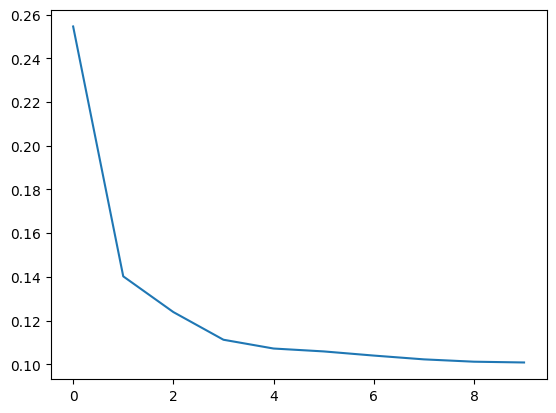

In [6]:
# convert the training history to a dataframe
history_df = pd.DataFrame(history.history)
# use Pandas native plot method
history_df['loss'].plot()